# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [67]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

os.makedirs("images", exist_ok=True)   # charts for the README are saved here

## Exploratory Data Analysis  
- Load in the cleaned data

In [68]:
df = pd.read_csv("aviation_cleaned.csv", parse_dates=["Event.Date"])
df["Number.of.Engines"] = df["Number.of.Engines"].astype("Int64")
print(df.shape)
display(df.head())
display(df[["total_occupants", "severe_injury_rate", "destroyed"]].describe())

(60814, 31)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,total_occupants,severe_injuries,severe_injury_rate,destroyed,aircraft_type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,0,PIPER PA28R200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,0,CESSNA 140


,total_occupants,severe_injury_rate,destroyed
count,60814.000000,60814.000000,60814.000000
mean,4.838984,0.264268,0.207041
std,23.842313,0.425856,0.405189
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.500000,0.000000
max,699.000000,1.000000,1.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [69]:
# Thresholds used throughout (change here to test sensitivity)
MIN_N_MAKE = 30   # minimum accidents for a make (within a size class) to be ranked
MIN_N_TYPE = 10   # minimum accidents for an aircraft type (as required by the brief)

# Passenger threshold of 20: a plane type is "large" if the MEDIAN number of people on board
# across its recorded accidents is at least 20. The median is used rather than the maximum because
# a few mistaken records (e.g. 90 occupants on a 4-seat Piper) would otherwise push small types
# into "large". Side effect: freighter-only types (2-3 crew) count as small, which suits a
# "larger passenger models" question.
med_occ = df.groupby("aircraft_type")["total_occupants"].transform("median")
df["size_class"] = np.where(med_occ >= 20, "large", "small")

# 1 if at least one person was fatally/seriously injured in the accident (used for robust comparisons)
df["any_severe"] = (df["severe_injuries"] > 0).astype(int)

display(df.groupby("size_class").agg(accidents=("destroyed", "size"),
                                     makes=("Make", "nunique"),
                                     types=("aircraft_type", "nunique")))

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (works on Series)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def summarise(data, by):
    """Per-group sample size, destroyed rate and mean severe-injury rate, each with a 95% CI."""
    g = data.groupby(by).agg(n=("destroyed", "size"),
                             destroyed_k=("destroyed", "sum"),
                             destroyed_rate=("destroyed", "mean"),
                             mean_severe=("severe_injury_rate", "mean"),
                             sd_severe=("severe_injury_rate", "std"),
                             any_k=("any_severe", "sum"))
    g["any_rate"] = g["any_k"] / g["n"]
    g["a_lo"], g["a_hi"] = wilson(g["any_k"], g["n"])
    g["d_lo"], g["d_hi"] = wilson(g["destroyed_k"], g["n"])
    g["d_lo"] = g["d_lo"].clip(lower=0)
    half = 1.96 * g["sd_severe"].fillna(0) / np.sqrt(g["n"])
    g["s_lo"] = (g["mean_severe"] - half).clip(lower=0)
    g["s_hi"] = (g["mean_severe"] + half).clip(upper=1)
    # Small-sample fix: if no serious/fatal injuries were seen in n accidents, a plain mean +/- SE
    # gives a misleading 0-0 interval. The "rule of three" upper bound (about 3/n) is used instead.
    never = g["mean_severe"] == 0
    g.loc[never, "s_hi"] = (3 / g.loc[never, "n"]).clip(upper=1)
    return g

def lowest(tbl, col, k):
    """The k groups with the lowest value of col; ties go to the group with more accidents."""
    return tbl.sort_values([col, "n"], ascending=[True, False]).head(k)

small = df[df["size_class"] == "small"]
large = df[df["size_class"] == "large"]

,accidents,makes,types
size_class,,,
large,1304,11,330
small,59510,63,3052


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

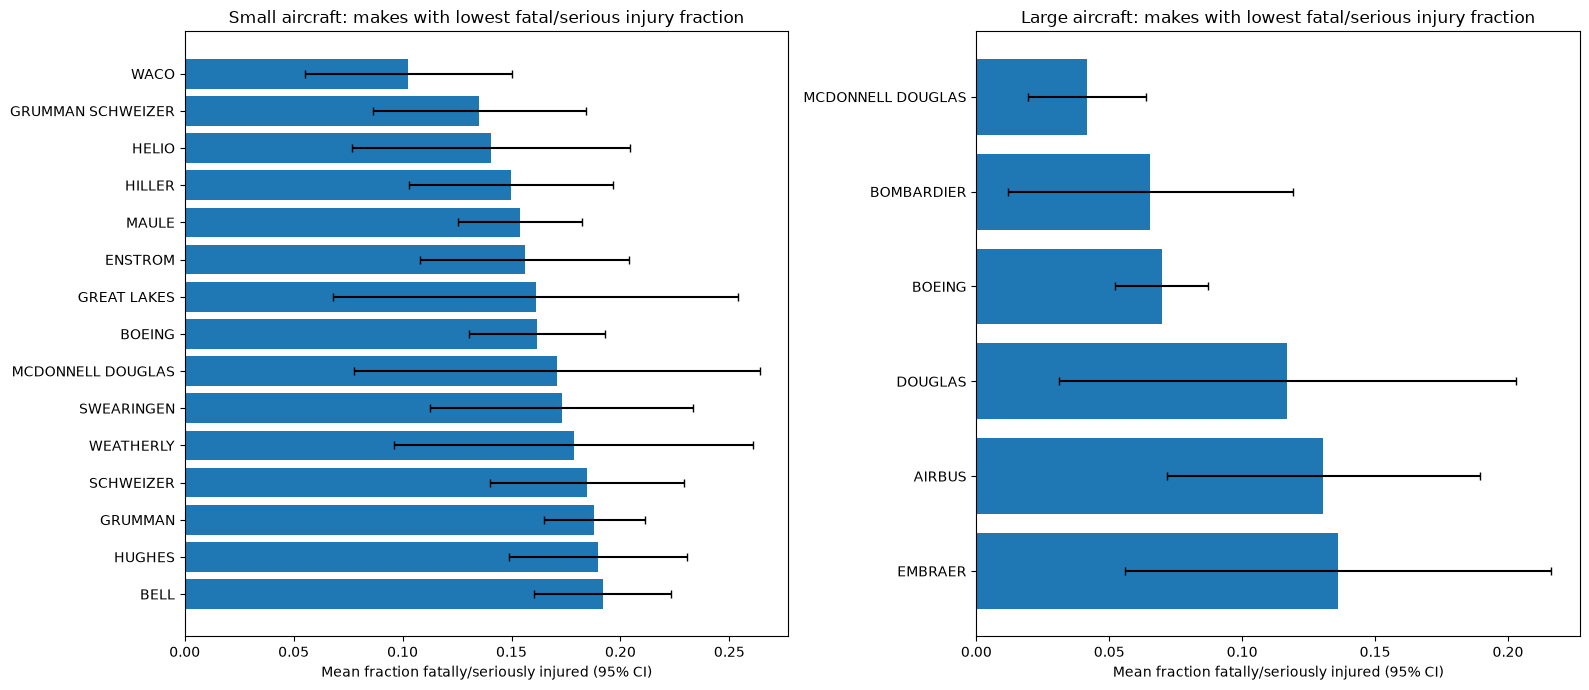

,n,mean_severe,s_lo,s_hi
Make,,,,
WACO,138,0.103,0.055,0.150
GRUMMAN SCHWEIZER,186,0.135,0.087,0.184
HELIO,105,0.141,0.077,0.205
HILLER,206,0.150,0.103,0.196
MAULE,567,0.154,0.125,0.182
ENSTROM,205,0.156,0.108,0.204
GREAT LAKES,59,0.161,0.068,0.254
BOEING,470,0.162,0.130,0.193
MCDONNELL DOUGLAS,59,0.171,0.078,0.264


,n,mean_severe,s_lo,s_hi
Make,,,,
MCDONNELL DOUGLAS,223,0.042,0.019,0.064
BOMBARDIER,72,0.065,0.012,0.119
BOEING,711,0.070,0.052,0.087
DOUGLAS,46,0.117,0.031,0.203
AIRBUS,116,0.131,0.072,0.189
EMBRAER,62,0.136,0.056,0.216


In [70]:
make_small = summarise(small, "Make")
make_small = make_small[make_small["n"] >= MIN_N_MAKE]
make_large = summarise(large, "Make")
make_large = make_large[make_large["n"] >= MIN_N_MAKE]

low_small = lowest(make_small, "mean_severe", 15)
low_large = lowest(make_large, "mean_severe", 15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, tbl, title in zip(axes, [low_small, low_large], ["Small aircraft", "Large aircraft"]):
    tbl = tbl.sort_values("mean_severe", ascending=False)
    ax.barh(tbl.index, tbl["mean_severe"],
            xerr=[tbl["mean_severe"] - tbl["s_lo"], tbl["s_hi"] - tbl["mean_severe"]], capsize=3)
    ax.set_title(f"{title}: makes with lowest fatal/serious injury fraction")
    ax.set_xlabel("Mean fraction fatally/seriously injured (95% CI)")
plt.tight_layout()
plt.savefig("images/lowest_injury_makes.png", dpi=150, bbox_inches="tight")
plt.show()

display(low_small[["n", "mean_severe", "s_lo", "s_hi"]].round(3))
display(low_large[["n", "mean_severe", "s_lo", "s_hi"]].round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

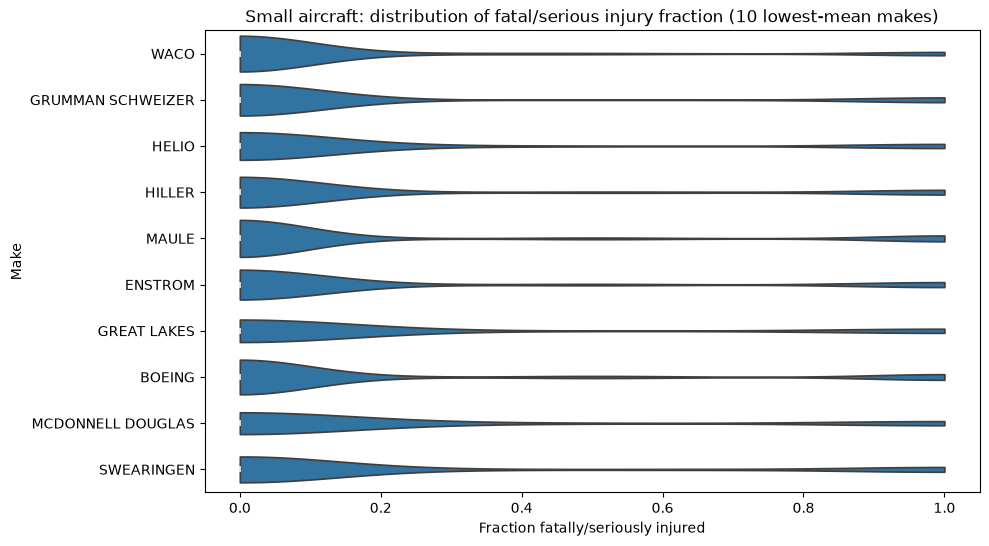

In [71]:
top10_small = lowest(make_small, "mean_severe", 10).index.tolist()

plt.figure(figsize=(10, 6))
sns.violinplot(data=small[small["Make"].isin(top10_small)],
               x="severe_injury_rate", y="Make", order=top10_small, orient="h", cut=0)
plt.title("Small aircraft: distribution of fatal/serious injury fraction (10 lowest-mean makes)")
plt.xlabel("Fraction fatally/seriously injured")
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

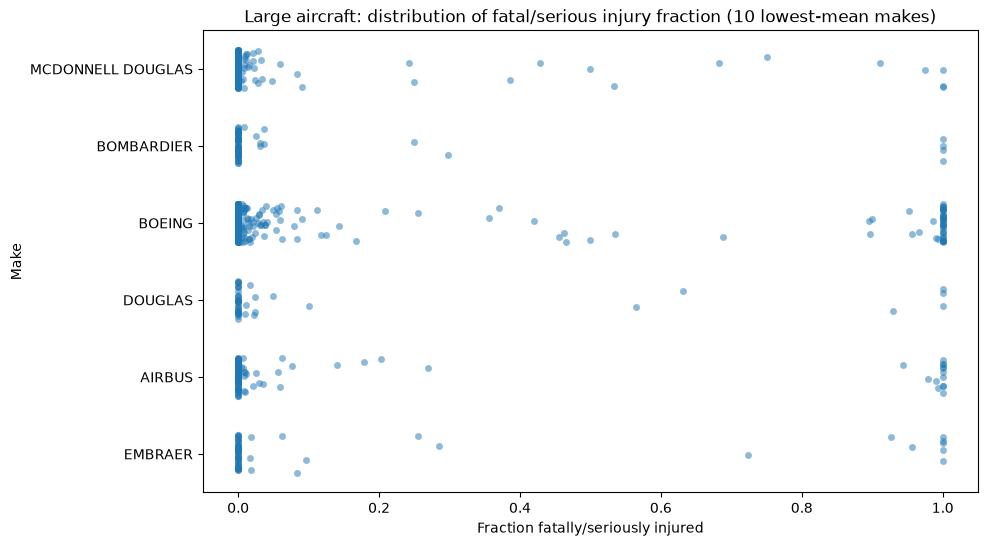

In [72]:
top10_large = lowest(make_large, "mean_severe", 10).index.tolist()

plt.figure(figsize=(10, 6))
sns.stripplot(data=large[large["Make"].isin(top10_large)],
              x="severe_injury_rate", y="Make", order=top10_large, orient="h",
              jitter=0.25, alpha=0.5)
plt.title("Large aircraft: distribution of fatal/serious injury fraction (10 lowest-mean makes)")
plt.xlabel("Fraction fatally/seriously injured")
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

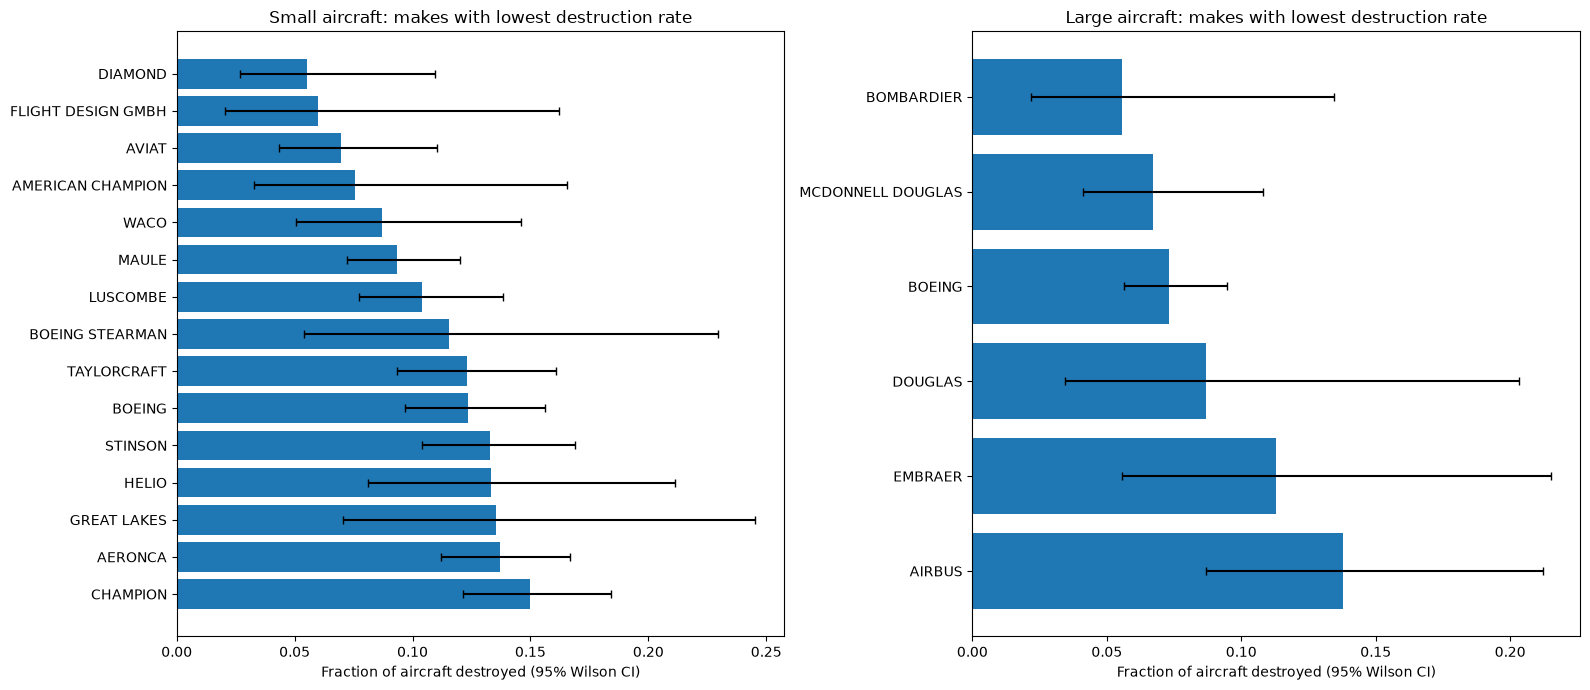

,n,destroyed_rate,d_lo,d_hi
Make,,,,
DIAMOND,127,0.055,0.027,0.109
FLIGHT DESIGN GMBH,50,0.060,0.021,0.162
AVIAT,229,0.070,0.043,0.110
AMERICAN CHAMPION,66,0.076,0.033,0.165
WACO,138,0.087,0.050,0.146
MAULE,567,0.093,0.072,0.120
LUSCOMBE,385,0.104,0.077,0.138
BOEING STEARMAN,52,0.115,0.054,0.230
TAYLORCRAFT,365,0.123,0.093,0.161


,n,destroyed_rate,d_lo,d_hi
Make,,,,
BOMBARDIER,72,0.056,0.022,0.134
MCDONNELL DOUGLAS,223,0.067,0.041,0.108
BOEING,711,0.073,0.056,0.095
DOUGLAS,46,0.087,0.034,0.203
EMBRAER,62,0.113,0.056,0.215
AIRBUS,116,0.138,0.087,0.212


In [73]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
low_dest = {}
for ax, tbl, title in zip(axes, [make_small, make_large], ["Small aircraft", "Large aircraft"]):
    best = lowest(tbl, "destroyed_rate", 15)
    low_dest[title] = best
    best = best.sort_values("destroyed_rate", ascending=False)
    ax.barh(best.index, best["destroyed_rate"],
            xerr=[best["destroyed_rate"] - best["d_lo"], best["d_hi"] - best["destroyed_rate"]], capsize=3)
    ax.set_title(f"{title}: makes with lowest destruction rate")
    ax.set_xlabel("Fraction of aircraft destroyed (95% Wilson CI)")
plt.tight_layout()
plt.savefig("images/lowest_destruction_makes.png", dpi=150, bbox_inches="tight")
plt.show()

low_dest_small, low_dest_large = low_dest["Small aircraft"], low_dest["Large aircraft"]
display(low_dest_small[["n", "destroyed_rate", "d_lo", "d_hi"]].round(3))
display(low_dest_large[["n", "destroyed_rate", "d_lo", "d_hi"]].round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [74]:
# Makes that appear in BOTH the lowest-injury and lowest-destruction lists
for label, inj, dest, tbl in [("small", low_small, low_dest_small, make_small),
                              ("large", low_large, low_dest_large, make_large)]:
    both = inj.index.intersection(dest.index)
    print(f"--- {label} aircraft: makes in both top-15 lists ---")
    display(tbl.loc[both, ["n", "mean_severe", "s_lo", "s_hi",
                           "destroyed_rate", "d_lo", "d_hi"]].round(3))

--- small aircraft: makes in both top-15 lists ---


,n,mean_severe,s_lo,s_hi,destroyed_rate,d_lo,d_hi
Make,,,,,,,
WACO,138,0.103,0.055,0.150,0.087,0.050,0.146
HELIO,105,0.141,0.077,0.205,0.133,0.081,0.211
MAULE,567,0.154,0.125,0.182,0.093,0.072,0.120
GREAT LAKES,59,0.161,0.068,0.254,0.136,0.070,0.245
BOEING,470,0.162,0.130,0.193,0.123,0.097,0.156


--- large aircraft: makes in both top-15 lists ---


,n,mean_severe,s_lo,s_hi,destroyed_rate,d_lo,d_hi
Make,,,,,,,
MCDONNELL DOUGLAS,223,0.042,0.019,0.064,0.067,0.041,0.108
BOMBARDIER,72,0.065,0.012,0.119,0.056,0.022,0.134
BOEING,711,0.070,0.052,0.087,0.073,0.056,0.095
DOUGLAS,46,0.117,0.031,0.203,0.087,0.034,0.203
AIRBUS,116,0.131,0.072,0.189,0.138,0.087,0.212
EMBRAER,62,0.136,0.056,0.216,0.113,0.056,0.215


### Discussion: makes (small vs large)

**Small aircraft.** Among small-aircraft makes with at least 30 accidents, the lowest mean fatal/serious injury fractions belong to Waco (0.103, n = 138), Grumman Schweizer (0.135, n = 186), Helio (0.141, n = 105), Hiller (0.150) and Maule (0.154, n = 567). The lowest destruction rates belong to Diamond (5.5%, n = 127), Flight Design (6.0%, n = 50), Aviat (7.0%, n = 229), American Champion (7.6%) and Waco (8.7%). The makes in both top-15 lists are Waco, Helio, Maule, Great Lakes and Boeing. The "Boeing" rows in the small group appear to be mostly Stearman biplanes (models A75N1, B75N1, E75) plus a few 747 records with small crews (likely freighters), so they are not a recommendation for airline buyers.

**How reliable is the ranking?** Neighbouring makes have heavily overlapping 95% confidence intervals (for example Waco 0.055-0.150 and Maule 0.125-0.182), so the exact order inside the top group should not be over-read. The sensible reading is a *tier* of makes with low injury and destruction rates. Maule is the best-evidenced member of that tier: low rates (injury fraction 0.154, destroyed 9.3%) together with by far the largest sample (567 accidents), which gives narrow intervals (injury 0.125-0.182, destroyed 7.2%-12.0%). Waco and Helio look good but rest on only 105-138 accidents.

**Distributions.** The injury fraction per accident is not bell-shaped. In small aircraft 70% of accidents have no fatal or serious injuries, 24% have *everyone* on board killed or seriously hurt, and only 6% fall in between. This is why the violin plots pile up at 0 with a second bump at 1, and why a make's mean mostly reflects how often an accident turns into an "everyone is hurt" event.

**Large aircraft.** Only 6 large-aircraft makes have at least 30 accidents. McDonnell Douglas (injury fraction 0.042, 95% CI 0.019-0.064, n = 223; destroyed 6.7%), Boeing (0.070, 0.052-0.087, n = 711; destroyed 7.3%) and Bombardier (0.065, n = 72; destroyed 5.6%) have the lowest rates. Douglas (0.117), Airbus (0.131; destroyed 13.8%) and Embraer (0.136; destroyed 11.3%) are higher. McDonnell Douglas's whole interval (up to 0.064) sits below Airbus's lower bound (0.072), so that difference is likely real; Boeing's and Airbus's intervals overlap, so those two cannot be separated confidently. Large-aircraft accidents also have a different shape: 81% had nobody seriously hurt and only 5% had everyone hurt, which is why their means are so much lower than for small aircraft.

**Recommendation (makes).** *Small:* Maule (best evidence), with Waco, Helio and Diamond as strong secondary options. *Large:* McDonnell Douglas and Boeing (large samples and the lowest rates), with Bombardier as a promising but less certain third.

**Limits.** These are rates *given that an accident occurred*. The data has no flight hours or number of flights, so it says nothing about how often each make has accidents; a make with many accidents (Boeing) may simply have a much bigger fleet.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

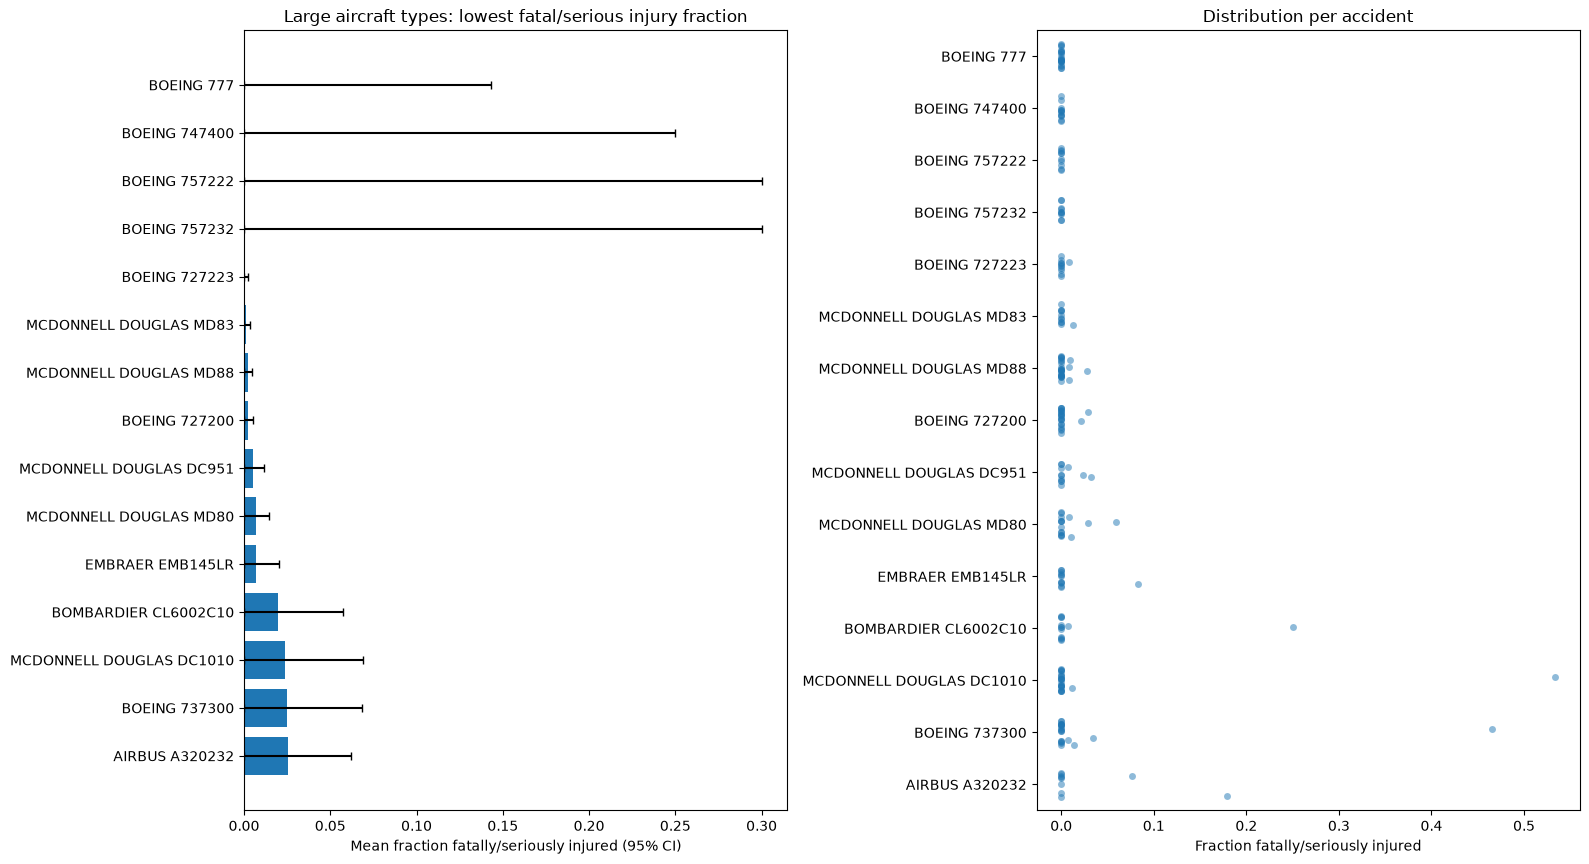

,n,mean_severe,s_lo,s_hi,destroyed_rate
aircraft_type,,,,,
BOEING 777,21,0.000,0.0,0.143,0.048
BOEING 747400,12,0.000,0.0,0.250,0.000
BOEING 757222,10,0.000,0.0,0.300,0.000
BOEING 757232,10,0.000,0.0,0.300,0.000
BOEING 727223,11,0.001,0.0,0.002,0.000
MCDONNELL DOUGLAS MD83,11,0.001,0.0,0.003,0.000
MCDONNELL DOUGLAS MD88,26,0.002,0.0,0.004,0.000
BOEING 727200,22,0.002,0.0,0.005,0.000
MCDONNELL DOUGLAS DC951,12,0.005,0.0,0.011,0.083


In [75]:
def plot_types(tbl, data, title):
    """Bar chart of mean severe-injury fraction (95% CI) + strip plot of the raw distribution."""
    order = tbl.sort_values("mean_severe").index.tolist()
    fig, axes = plt.subplots(1, 2, figsize=(16, max(4, 0.45 * len(order) + 2)))
    t = tbl.loc[order[::-1]]
    axes[0].barh(t.index, t["mean_severe"],
                 xerr=[t["mean_severe"] - t["s_lo"], t["s_hi"] - t["mean_severe"]], capsize=3)
    axes[0].set_xlabel("Mean fraction fatally/seriously injured (95% CI)")
    axes[0].set_title(title)
    sns.stripplot(data=data[data["aircraft_type"].isin(order)], x="severe_injury_rate",
                  y="aircraft_type", order=order, orient="h", jitter=0.25, alpha=0.5, ax=axes[1])
    axes[1].set_xlabel("Fraction fatally/seriously injured")
    axes[1].set_ylabel("")
    axes[1].set_title("Distribution per accident")
    plt.tight_layout()
    plt.show()

type_large = summarise(large, "aircraft_type")
type_large = type_large[type_large["n"] >= MIN_N_TYPE]
best_large = lowest(type_large, "mean_severe", 15)

plot_types(best_large, large, "Large aircraft types: lowest fatal/serious injury fraction")
display(best_large[["n", "mean_severe", "s_lo", "s_hi", "destroyed_rate"]].round(3))

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

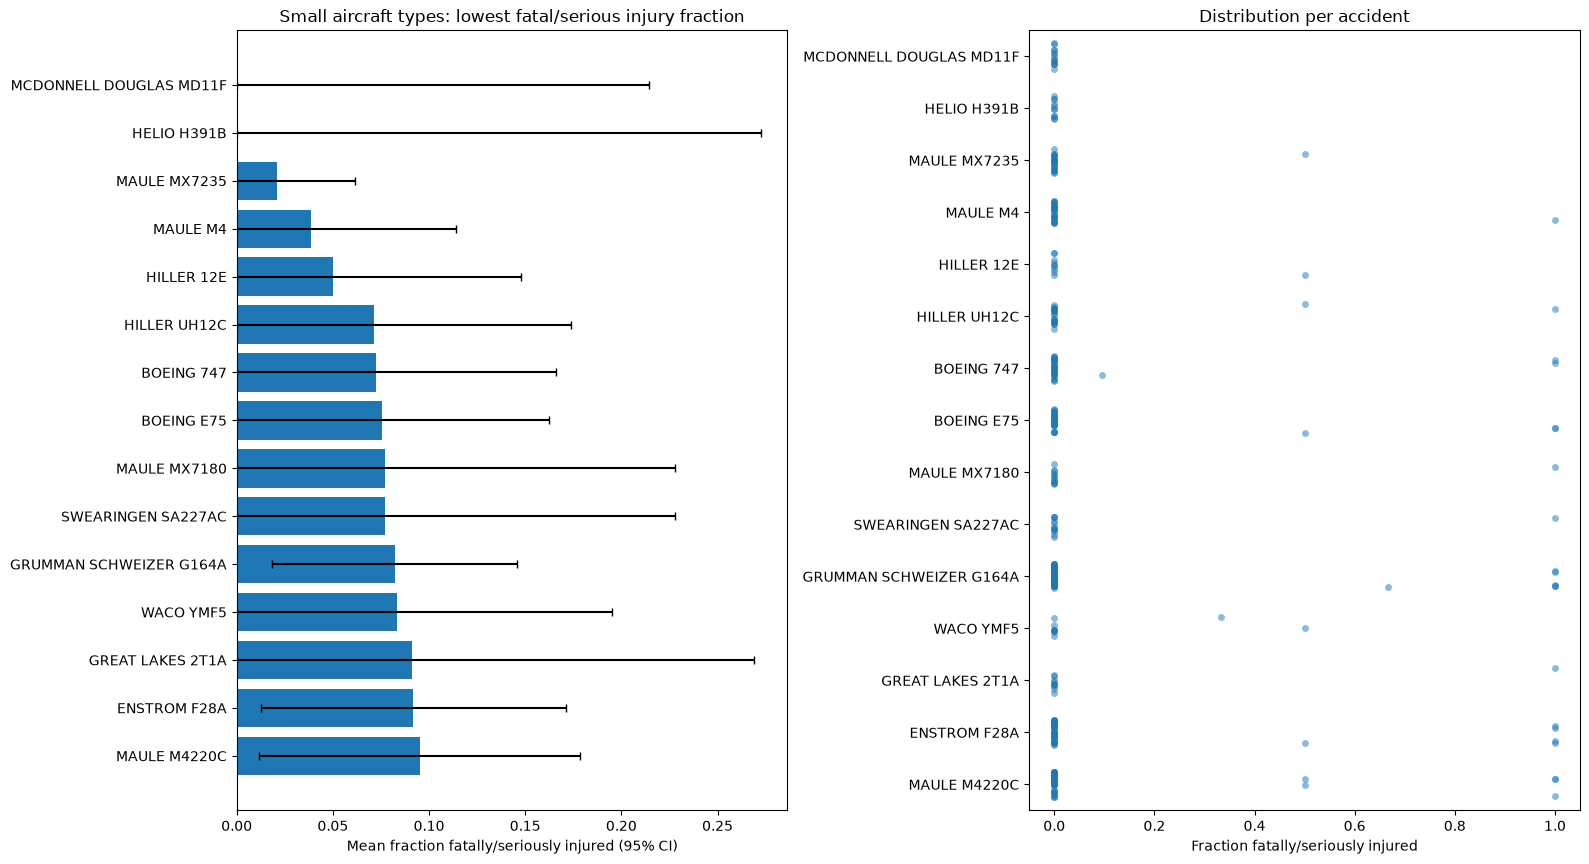

,n,mean_severe,s_lo,s_hi,destroyed_rate
aircraft_type,,,,,
MCDONNELL DOUGLAS MD11F,14,0.000,0.000,0.214,0.071
HELIO H391B,11,0.000,0.000,0.273,0.091
MAULE MX7235,24,0.021,0.000,0.062,0.042
MAULE M4,26,0.038,0.000,0.114,0.038
HILLER 12E,10,0.050,0.000,0.148,0.300
HILLER UH12C,21,0.071,0.000,0.174,0.000
BOEING 747,29,0.072,0.000,0.166,0.069
BOEING E75,33,0.076,0.000,0.162,0.121
MAULE MX7180,13,0.077,0.000,0.228,0.000


In [76]:
# Smaller planes: restrict to the 10 makes with the lowest mean serious/fatal injury fraction
small_sub = small[small["Make"].isin(top10_small)]
type_small = summarise(small_sub, "aircraft_type")
type_small = type_small[type_small["n"] >= MIN_N_TYPE]
best_small = lowest(type_small, "mean_severe", 15)

plot_types(best_small, small_sub, "Small aircraft types: lowest fatal/serious injury fraction")
display(best_small[["n", "mean_severe", "s_lo", "s_hi", "destroyed_rate"]].round(3))

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [77]:
# Combined ranking per size class. Types are ranked on the UPPER 95% (Wilson) bounds of
#   - the share of accidents with at least one fatal/serious injury, and
#   - the share of accidents that destroy the aircraft,
# so a type only ranks well if even the pessimistic estimate is good. This favours well-sampled
# types over ones that look perfect from only 10 accidents.
def shortlist(data, label, top=5):
    t = summarise(data, "aircraft_type")
    t = t[t["n"] >= MIN_N_TYPE].copy()
    t["rank_sum"] = t["a_hi"].rank() + t["d_hi"].rank()
    print(f"--- {label}: best {top} aircraft types (lowest upper bounds of injury + destruction) ---")
    best = t.sort_values(["rank_sum", "n"], ascending=[True, False]).head(top)
    display(best[["n", "any_rate", "a_lo", "a_hi", "mean_severe", "destroyed_rate", "d_lo", "d_hi"]].round(3))

shortlist(small, "small")
shortlist(large, "large")

--- small: best 5 aircraft types (lowest upper bounds of injury + destruction) ---


,n,any_rate,a_lo,a_hi,mean_severe,destroyed_rate,d_lo,d_hi
aircraft_type,,,,,,,,
CESSNA 180,587,0.141,0.116,0.172,0.113,0.075,0.056,0.099
PIPER PA20,132,0.083,0.047,0.143,0.080,0.053,0.026,0.105
CESSNA 180A,61,0.066,0.026,0.157,0.066,0.033,0.009,0.112
PIPER PA18,658,0.173,0.146,0.204,0.154,0.081,0.062,0.104
CESSNA 170B,377,0.156,0.123,0.197,0.136,0.085,0.061,0.117


--- large: best 5 aircraft types (lowest upper bounds of injury + destruction) ---


,n,any_rate,a_lo,a_hi,mean_severe,destroyed_rate,d_lo,d_hi
aircraft_type,,,,,,,,
BOEING 727200,22,0.091,0.025,0.278,0.002,0.000,0.000,0.149
MCDONNELL DOUGLAS DC1010,23,0.087,0.024,0.268,0.024,0.043,0.008,0.210
BOEING 777,21,0.000,0.000,0.155,0.000,0.048,0.008,0.227
BOEING 737,111,0.225,0.157,0.311,0.126,0.108,0.063,0.180
MCDONNELL DOUGLAS MD88,26,0.154,0.061,0.335,0.002,0.000,0.000,0.129


### Discussion: specific airplane types

**Larger planes.** Only 35 large-aircraft types have the minimum of 10 accidents, and just 2 have 30 or more, which is too little data to separate individual models with confidence. The Boeing 727-200 (n = 22), DC-10-10 (n = 23), Boeing 777 (n = 21), Boeing 737 (n = 111) and MD-88 (n = 26) rank best on the conservative score, but the upper bounds for the share of accidents with any fatal/serious injury (0.155-0.335) and for destruction (0.129-0.227) overlap almost completely. Types with a mean of 0 are not proven safer: the 777 had no serious/fatal injuries in 21 accidents, but that only bounds the true share below about 15%, and the 747-400 (0 of 12) only below about 24%. The Boeing 737 label (111 accidents) also has a higher injury fraction (0.126) than Boeing overall (0.070), a reminder that a manufacturer average hides variation between models. The large-aircraft recommendation should therefore be made at manufacturer level (McDonnell Douglas, Boeing), and the types above treated as a shortlist for further review rather than proven winners.

**Smaller planes.** 717 small-aircraft types have at least 10 accidents. Ranked on the conservative score, the best are the Cessna 180 (n = 587; fatal/serious injury in 14.1% of accidents, upper bound 17.2%; destroyed 7.5%), Piper PA-20 (n = 132; 8.3%; destroyed 5.3%), Cessna 180A (n = 61; 6.6%; destroyed 3.3%), Piper PA-18 (n = 658; 17.3%; destroyed 8.1%), Cessna 170B (n = 377; 15.6%; destroyed 8.5%) and Cessna 185 (n = 258; 14.0%; destroyed 8.9%). These are all classic tail-wheel utility designs with large accident counts, so the estimates are comparatively reliable. Two cautions: part of their good record may reflect how they are flown (often low-speed, visual flying by experienced pilots) and not the design alone; and make-level averages hide model differences, since Cessna as a whole is not in the lowest-15 make list although the 180 and 185 are among the best types.

**Recommendation (types).** *Small:* Cessna 180/185 and Piper PA-18/PA-20 families (with Maule at make level). *Large:* models from Boeing and McDonnell Douglas, using the shortlist above only as a starting point.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

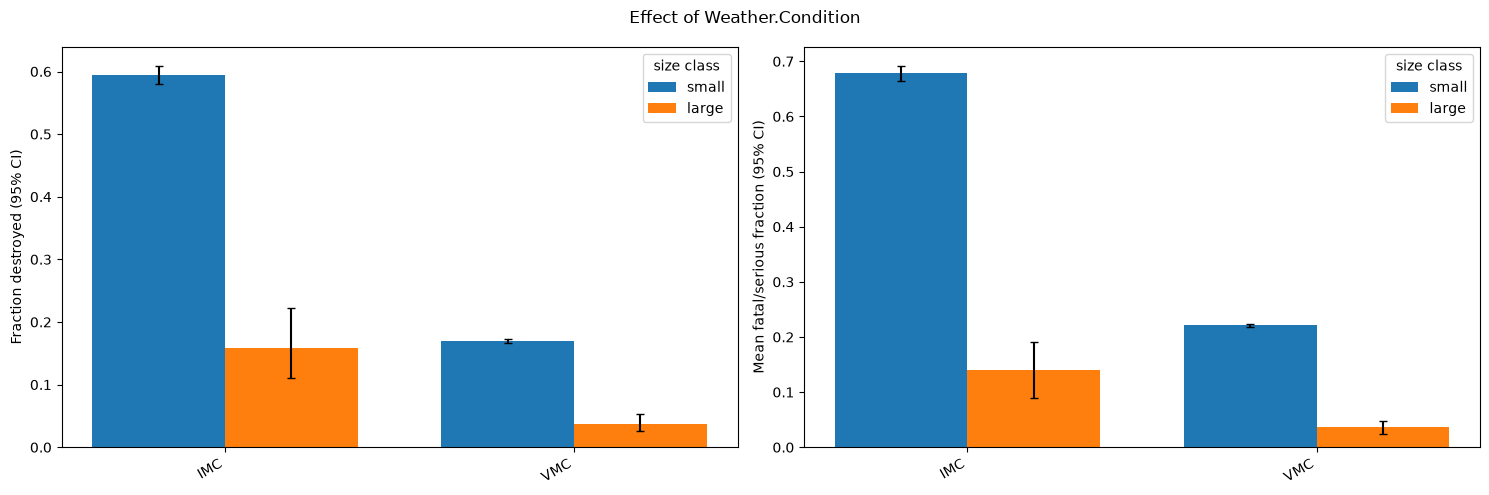

n  destroyed_rate   d_lo   d_hi  \
size_class Weather.Condition                                        
large      IMC                  164           0.159  0.111  0.222   
           VMC                  828           0.037  0.026  0.053   
small      IMC                 4555           0.595  0.580  0.609   
           VMC                53038           0.169  0.166  0.172   

                              mean_severe   s_lo   s_hi  
size_class Weather.Condition                             
large      IMC                      0.141  0.090  0.192  
           VMC                      0.036  0.025  0.048  
small      IMC                      0.678  0.665  0.691  
           VMC                      0.221  0.218  0.224

large: destroyed vs Weather.Condition: chi-square p = 3.538e-09 | severe-injury fraction vs Weather.Condition: Kruskal-Wallis p = 9.355e-09
small: destroyed vs Weather.Condition: chi-square p = 0 | severe-injury fraction vs Weather.Condition: Kruskal-Wallis p = 0


In [78]:
def grouped_bar(ax, tbl, val, lo, hi, ylabel):
    """Grouped bars (small vs large) per factor level, with asymmetric 95% CI error bars."""
    levels = sorted(tbl.index.get_level_values(1).unique(), key=str)
    width = 0.38
    present = tbl.index.get_level_values("size_class").unique()
    for i, sc in enumerate(["small", "large"]):
        if sc not in present:
            continue
        sub = tbl.xs(sc, level="size_class").reindex(levels)
        x = np.arange(len(levels)) + (i - 0.5) * width
        ax.bar(x, sub[val], width, label=sc,
               yerr=[(sub[val] - sub[lo]).fillna(0), (sub[hi] - sub[val]).fillna(0)], capsize=3)
    ax.set_xticks(np.arange(len(levels)))
    ax.set_xticklabels(levels, rotation=30, ha="right")
    ax.set_ylabel(ylabel)
    ax.legend(title="size class")

def factor_analysis(factor, min_n=MIN_N_MAKE):
    d = df.dropna(subset=[factor]).copy()
    d[factor] = d[factor].astype(str)

    tbl = summarise(d, ["size_class", factor])
    tbl = tbl[tbl["n"] >= min_n]      # only compare groups with enough samples

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    grouped_bar(axes[0], tbl, "destroyed_rate", "d_lo", "d_hi", "Fraction destroyed (95% CI)")
    grouped_bar(axes[1], tbl, "mean_severe", "s_lo", "s_hi", "Mean fatal/serious fraction (95% CI)")
    fig.suptitle(f"Effect of {factor}")
    plt.tight_layout()
    plt.savefig("images/factor_" + factor.replace(".", "_").lower() + ".png", dpi=150, bbox_inches="tight")
    plt.show()
    display(tbl[["n", "destroyed_rate", "d_lo", "d_hi", "mean_severe", "s_lo", "s_hi"]].round(3))

    # Significance tests within each size class (so size is not a confounder)
    for sc, sub in d.groupby("size_class"):
        sub = sub[sub[factor].map(sub[factor].value_counts()) >= min_n]
        if sub[factor].nunique() < 2:
            continue
        try:
            p_d = stats.chi2_contingency(pd.crosstab(sub[factor], sub["destroyed"]))[1]
        except ValueError:
            p_d = float("nan")
        try:
            p_s = stats.kruskal(*[g["severe_injury_rate"].values for _, g in sub.groupby(factor)])[1]
        except ValueError:
            p_s = float("nan")
        print(f"{sc}: destroyed vs {factor}: chi-square p = {p_d:.4g} | "
              f"severe-injury fraction vs {factor}: Kruskal-Wallis p = {p_s:.4g}")

# Factor 1
factor_analysis("Weather.Condition")

**Factor 1: Weather condition (VMC vs IMC) - discussion**

Accidents in instrument conditions (IMC, i.e. cloud or poor visibility) are far more severe than accidents in visual conditions (VMC), in both size classes.

- **Small aircraft:** the aircraft was destroyed in 59.5% of IMC accidents versus 16.9% of VMC accidents (95% CIs 58.0%-60.9% vs 16.6%-17.2%). The mean fatal/serious injury fraction is 0.678 versus 0.221.
- **Large aircraft:** destroyed in 15.9% of IMC accidents (11.1%-22.2%) versus 3.7% of VMC accidents (2.6%-5.3%). Injury fraction 0.141 versus 0.036.

The intervals do not come close to overlapping and the tests agree (chi-square for destruction / Kruskal-Wallis for injury fraction: p effectively 0 / effectively 0 for small aircraft, p = 3.5e-09 / 9.4e-09 for large aircraft). The small-aircraft IMC group is big (4,555 accidents), so that estimate is very precise; the large-aircraft IMC group is smaller (164) but the gap is still clear. In relative terms, an IMC accident is about 3.5 times as likely to destroy a small aircraft, and about 4 times as likely to destroy a large one.

**Interpretation and caveats.** Because the gap appears inside each size class, it is not explained by aircraft size. IMC accidents are only 7.9% of small-aircraft and 16.5% of large-aircraft accidents, and the data has no count of how many flights take place in IMC, so we cannot say IMC flying is riskier *per flight*, only that when an accident happens in IMC it is much worse. This is an association; pilot experience, instrument rating and night flying are likely contributors. **For the client:** weather and operating profile (how much instrument flying an operator does) should weigh heavily in underwriting, whichever aircraft is chosen.

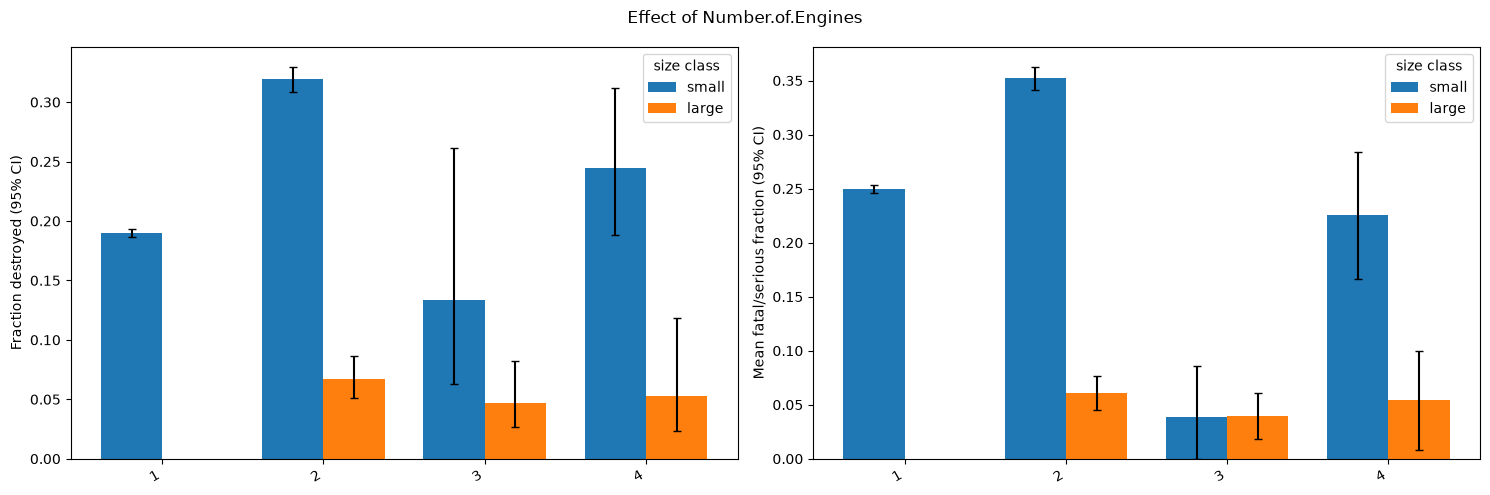

n  destroyed_rate   d_lo   d_hi  \
size_class Number.of.Engines                                        
large      2                    765           0.067  0.051  0.087   
           3                    234           0.047  0.026  0.082   
           4                     94           0.053  0.023  0.119   
small      1                  50685           0.190  0.187  0.193   
           2                   7293           0.319  0.308  0.330   
           3                     45           0.133  0.063  0.262   
           4                    184           0.245  0.188  0.311   

                              mean_severe   s_lo   s_hi  
size_class Number.of.Engines                             
large      2                        0.061  0.045  0.077  
           3                        0.040  0.018  0.061  
           4                        0.054  0.008  0.100  
small      1                        0.249  0.246  0.253  
           2                        0.352  0.342  0.363  
           3                        0.039  0.000  0.085  
           4                        0.225  0.166  0.284

large: destroyed vs Number.of.Engines: chi-square p = 0.5166 | severe-injury fraction vs Number.of.Engines: Kruskal-Wallis p = 0.5029
small: destroyed vs Number.of.Engines: chi-square p = 6.565e-141 | severe-injury fraction vs Number.of.Engines: Kruskal-Wallis p = 1.379e-85


In [79]:
# Factor 2
factor_analysis("Number.of.Engines")

**Factor 2: Number of engines - discussion**

The effect of engine count depends on the size class, which is why every comparison is made within a size class.

- **Small aircraft:** single-engine planes were destroyed in 19.0% of accidents (18.7%-19.3%, n = 50,685) and had a mean injury fraction of 0.249; twin-engine planes were destroyed in 31.9% (30.8%-33.0%, n = 7,293) with an injury fraction of 0.352. The difference is statistically very strong (chi-square p 6.6e-141 and Kruskal-Wallis p 1.4e-85). The 3- and 4-engine small groups are tiny and mixed, so they are not interpreted.
- **Large aircraft:** two-, three- and four-engine types were destroyed in 6.7%, 4.7% and 5.3% of accidents, with injury fractions of 0.061, 0.040 and 0.054. All the intervals overlap and the tests find no significant difference (chi-square p = 0.52, Kruskal-Wallis p = 0.50).

**Interpretation and caveats.** Twin-engine accidents in small aircraft are *worse* than single-engine ones, the opposite of the common assumption that a second engine adds safety. The data cannot say why, and this is an association, not proof that a second engine is harmful. Twins are heavier and faster, carry more people, and are often flown in more demanding conditions (business and instrument flying), and an engine failure on a twin can itself cause loss of control. For large passenger aircraft engine count does not separate the groups, so it should not drive the choice. **For the client:** do not treat "twin-engine" as a safety credential for small aircraft, and look at specific models and operating profile instead.

## Overall recommendations

| | Small aircraft | Larger passenger aircraft |
|---|---|---|
| **Makes** | Maule (best evidence), Waco, Helio, Diamond | McDonnell Douglas, Boeing (Bombardier promising, fewer accidents) |
| **Models** | Cessna 180 / 180A / 185, Piper PA-18 / PA-20 | Models from Boeing and McDonnell Douglas; individual models cannot be separated with confidence |

**Factors:** weather condition (IMC accidents are far more severe) and number of engines (twin-engine small aircraft fare worse; no effect for large aircraft).

**Statistical care taken:** minimum sample sizes (30 accidents per make, 10 per type), 95% confidence intervals on every rate, a ranking based on upper bounds so thinly sampled types do not look better than they are, and significance tests within each size class.

**Limits:** the data covers accidents only, with no flight hours, so these are rates *given that an accident happened* and not how often accidents occur; injury counts include crew; and the findings are associations, not proof of cause.